# Step 4d — Feature Audit: Significance and Redundancy

**Question.** Before the engineered features go into a neural ranker, do they each contribute significantly to the ranking, and how much do they overlap?

**Why not p-values from a regression?** With 15.5M rows every coefficient is "significant", and ranking quality is measured per slate, not per row. The audit therefore asks the question that matters for the task: **does ranking quality on unseen users drop when a feature's information is destroyed?**

| Analysis | Method | Answers |
|---|---|---|
| Redundancy | Spearman correlation between features (monotone, robust to heavy tails), then hierarchical clustering into groups with average \|ρ\| ≥ 0.7 | Which features carry overlapping information |
| Significance | **Permutation importance** on the test slates: shuffle one feature's values, re-score, and measure the drop in NDCG@10 per slate. With ~25,800 test slates, the mean drop has a tight normal confidence interval; significance uses a **Bonferroni-corrected** one-sided test across all features | Whether each feature contributes beyond chance |
| Overlap-aware significance | Permute each **correlated group** jointly | Features that look useless alone because a near-duplicate substitutes for them |

Gain share (how often LightGBM split on a feature) is shown for reference only. It measures use, not contribution.

**Inputs:** `features.parquet` (55 features after Step 4b; Step 4c's seasonal columns are excluded if present). **Runtime:** ~25 min on Colab High-RAM CPU.

In [1]:
import os, time, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds
from scipy.stats import norm
from scipy.cluster.hierarchy import linkage, fcluster, leaves_list
from scipy.spatial.distance import squareform

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/JDSearch/Raw Data')
except ImportError:
    DATA_DIR = Path(os.environ.get('JD_DATA_DIR', '~/Downloads/JDsearch')).expanduser()
OUT_DIR = DATA_DIR / 'processed'
SEED = 42
USER_FRAC = 1.0           # share of train/val users used to fit the audit model; test slates are always all used
SEASONAL = ['cat3_festival_lift', 'u_festival_share', 'ucat3_fest_ord', 'ucat3_fest_share']

dset = ds.dataset(OUT_DIR / 'features.parquet')
FEATURES = [c for c in dset.schema.names if c not in ('user', 'wid', 'label', 'split') and c not in SEASONAL]
keep_user = np.random.default_rng(SEED + 1).random(200_000) < USER_FRAC   # not SEED: Step 2 drew the split from that same stream

def load(split, frac_filter=True):
    d = dset.to_table(columns=['user', 'label'] + FEATURES, filter=ds.field('split') == split).to_pandas()
    if frac_filter and USER_FRAC < 1:
        d = d[keep_user[d['user'].to_numpy()]]
    d = d.iloc[np.lexsort((np.random.default_rng(SEED).random(len(d)), d['user'].to_numpy()))]   # shuffle within slate
    return d[d.groupby('user')['label'].transform('max') > 0].reset_index(drop=True)

tr, va, te = load('train'), load('val'), load('test', frac_filter=False)
print(f'{len(FEATURES)} features | train {tr["user"].nunique():,} slates | val {va["user"].nunique():,} | '
      f'test {te["user"].nunique():,} (all)')

Mounted at /content/drive
55 features | train 120,081 slates | val 25,825 | test 25,822 (all)


## 1. Redundancy: which features overlap?

Spearman correlation on a 400k-row sample of the training slates. Features are clustered by average linkage on the distance 1 − |ρ| and cut at 0.3, so each group's members correlate at |ρ| ≥ 0.7 on average.

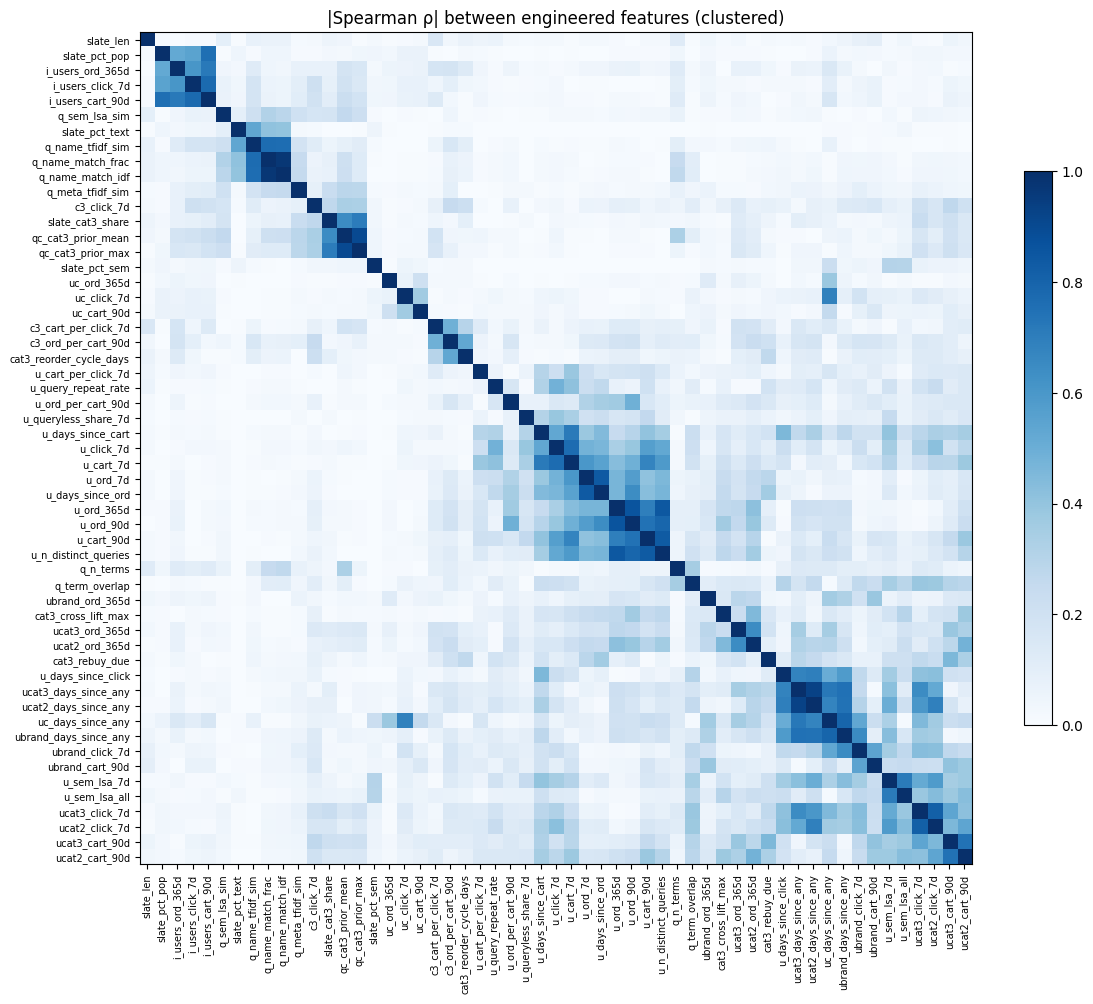

8 feature pairs with |ρ| >= 0.8:
  +0.972  q_name_match_frac  ~  q_name_match_idf
  +0.927  ucat3_days_since_any  ~  ucat2_days_since_any
  +0.899  qc_cat3_prior_mean  ~  qc_cat3_prior_max
  +0.863  u_ord_365d  ~  u_ord_90d
  +0.846  u_ord_365d  ~  u_n_distinct_queries
  -0.838  u_ord_7d  ~  u_days_since_ord
  +0.834  u_cart_90d  ~  u_n_distinct_queries
  +0.815  ucat3_click_7d  ~  ucat2_click_7d

10 correlated groups (|ρ| >= 0.7 on average), covering 25 of 55 features:
  group 1: ['i_users_click_7d', 'i_users_cart_90d']
  group 4: ['q_name_tfidf_sim', 'q_name_match_frac', 'q_name_match_idf']
  group 7: ['qc_cat3_prior_mean', 'qc_cat3_prior_max']
  group 17: ['u_click_7d', 'u_cart_7d']
  group 19: ['u_ord_7d', 'u_days_since_ord']
  group 20: ['u_cart_90d', 'u_ord_365d', 'u_ord_90d', 'u_n_distinct_queries']
  group 31: ['uc_days_since_any', 'ubrand_days_since_any', 'ucat3_days_since_any', 'ucat2_days_since_any']
  group 35: ['u_sem_lsa_7d', 'u_sem_lsa_all']
  group 36: ['ucat3_click_7d'

In [2]:
smp = tr.sample(min(400_000, len(tr)), random_state=SEED)[FEATURES]
arr = smp.rank().corr().fillna(0.0).to_numpy(copy=True)
np.fill_diagonal(arr, 1.0)
rho = pd.DataFrame(arr, index=FEATURES, columns=FEATURES)
dist = np.clip(1 - np.abs(arr), 0, None)
np.fill_diagonal(dist, 0.0)
Z = linkage(squareform(dist, checks=False), method='average')
cluster_of = pd.Series(fcluster(Z, t=0.3, criterion='distance'), index=FEATURES)
order = [FEATURES[i] for i in leaves_list(Z)]

fig, ax = plt.subplots(figsize=(12, 10.5))
im = ax.imshow(rho.loc[order, order].abs(), cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7)
ax.set_title('|Spearman ρ| between engineered features (clustered)')
fig.colorbar(im, ax=ax, shrink=0.6); plt.tight_layout(); plt.show()

pairs = [(a, b, rho.loc[a, b]) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(rho.loc[a, b]) >= 0.8]
print(f'{len(pairs)} feature pairs with |ρ| >= 0.8:')
for a, b, r in sorted(pairs, key=lambda x: -abs(x[2])):
    print(f'  {r:+.3f}  {a}  ~  {b}')
groups = {k: list(v.index) for k, v in cluster_of.groupby(cluster_of) if len(v) > 1}
print(f'\n{len(groups)} correlated groups (|ρ| >= 0.7 on average), covering '
      f'{sum(map(len, groups.values()))} of {len(FEATURES)} features:')
for k, members in groups.items():
    print(f'  group {k}: {members}')

## 2. Fit the reference model

Same LightGBM LambdaRank setup as Steps 2–4b (seed, shuffled slates, early stopping on validation NDCG@10), trained on all audited features.

In [3]:
import lightgbm as lgb, warnings
warnings.filterwarnings('ignore', message='.*eval_set.*deprecated')
warnings.filterwarnings('ignore', message='.*does not have valid feature names.*')
g_tr = tr.groupby('user', sort=False).size().to_numpy(); g_va = va.groupby('user', sort=False).size().to_numpy()
t0 = time.time()
model = lgb.LGBMRanker(objective='lambdarank', n_estimators=600, learning_rate=0.05, num_leaves=63,
                       min_child_samples=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                       random_state=SEED, n_jobs=-1, verbose=-1)
model.fit(tr[FEATURES], tr['label'], group=g_tr, eval_set=[(va[FEATURES], va['label'])], eval_group=[g_va],
          eval_at=[10], callbacks=[lgb.early_stopping(50, verbose=False)])
del tr, va; gc.collect()
print(f'trained in {time.time() - t0:.0f}s, best iteration {model.best_iteration_}')

def slate_ndcg(u, lab, score, k=10, seed=0):
    """NDCG@10 of every slate, in a fixed slate order (sorted by user), with random tie-breaking."""
    r = np.random.default_rng(seed).random(len(u))
    order = np.lexsort((r, -score, u))
    u_s, lab_s = u[order], lab[order]
    start = np.r_[0, np.flatnonzero(u_s[1:] != u_s[:-1]) + 1]
    size = np.diff(np.r_[start, len(u_s)])
    rank = np.arange(len(u_s)) - np.repeat(start, size)
    disc = np.where(rank < k, 1.0 / np.log2(rank + 2), 0.0)
    gid = np.repeat(np.arange(len(start)), size)
    dcg = np.bincount(gid, weights=(2 ** lab_s - 1) * disc)
    lab_i = lab[np.lexsort((-lab, u))]
    idcg = np.bincount(gid, weights=(2 ** lab_i - 1) * disc)
    return dcg / idcg

u_te, lab_te = te['user'].to_numpy(), te['label'].to_numpy().astype(np.float64)
X = te[FEATURES].copy(); del te; gc.collect()
base = slate_ndcg(u_te, lab_te, model.predict(X))
print(f'reference model test NDCG@10 = {base.mean():.4f} over {len(base):,} slates')

trained in 236s, best iteration 336
reference model test NDCG@10 = 0.4159 over 25,822 slates


## 3. Permutation importance with confidence intervals

For each feature (and then each correlated group, and each feature family), its values are shuffled across all test rows with one fixed permutation, and every slate is re-scored. The per-slate drop in NDCG@10 is averaged over ~25,800 slates, which gives a normal-approximation 95% CI. A feature counts as **significant** when its mean drop exceeds zero at a one-sided α = 0.05 after Bonferroni correction across all individual features.

In [4]:
rng = np.random.default_rng(SEED)
m_tests = len(FEATURES)
z_crit = norm.ppf(1 - 0.05 / m_tests)

def perm_drop(cols):
    idx = rng.permutation(len(X))
    saved = X[cols].to_numpy().copy()
    X[cols] = saved[idx]
    d = base - slate_ndcg(u_te, lab_te, model.predict(X))
    X[cols] = saved
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), d.mean() - 1.96 * se, d.mean() + 1.96 * se, d.mean() / se if se > 0 else 0.0

t0 = time.time()
rows = {f: perm_drop([f]) for f in FEATURES}
print(f'individual permutations: {time.time() - t0:.0f}s')
gain = pd.Series(model.booster_.feature_importance('gain'), index=FEATURES); gain /= gain.sum()
res = pd.DataFrame(rows, index=['ndcg_drop', 'ci_low', 'ci_high', 'z']).T
res['significant'] = res['z'] > z_crit
res['gain_share'] = gain
res['group'] = cluster_of.where(cluster_of.map(cluster_of.value_counts()) > 1)
print(f'Bonferroni threshold: z > {z_crit:.2f} (one-sided, {m_tests} tests)')
res.sort_values('ndcg_drop', ascending=False).round({'ndcg_drop': 5, 'ci_low': 5, 'ci_high': 5, 'z': 1, 'gain_share': 4})

individual permutations: 483s
Bonferroni threshold: z > 3.12 (one-sided, 55 tests)


,ndcg_drop,ci_low,ci_high,z,significant,gain_share,group
slate_pct_pop,0.12000,0.11656,0.12344,68.4,True,0.4841,NaN
i_users_click_7d,0.08195,0.07916,0.08473,57.6,True,0.0897,1.0
uc_days_since_any,0.03953,0.03769,0.04138,42.0,True,0.1398,31.0
i_users_cart_90d,0.02140,0.01960,0.02320,23.3,True,0.0145,1.0
i_users_ord_365d,0.01138,0.01002,0.01275,16.3,True,0.0132,NaN
q_name_tfidf_sim,0.01112,0.00948,0.01275,13.3,True,0.0212,4.0
slate_len,0.00718,0.00570,0.00866,9.5,True,0.0491,NaN
ubrand_days_since_any,0.00585,0.00467,0.00704,9.7,True,0.0088,31.0
c3_click_7d,0.00550,0.00428,0.00671,8.9,True,0.0095,NaN
slate_cat3_share,0.00456,0.00340,0.00573,7.7,True,0.0142,NaN


In [5]:
# overlap-aware: permute each correlated group jointly (one shared permutation keeps the group's internal correlation)
grp_rows = {}
for k, members in groups.items():
    dm, lo, hi, z = perm_drop(members)
    grp_rows[f'group {k} ({len(members)})'] = {'ndcg_drop': dm, 'ci_low': lo, 'ci_high': hi, 'z': z,
        'sum of individual drops': res.loc[members, 'ndcg_drop'].sum(),
        'members significant alone': int(res.loc[members, 'significant'].sum()), 'members': ', '.join(members)}
grp = pd.DataFrame(grp_rows).T if grp_rows else pd.DataFrame(columns=['ndcg_drop', 'z', 'members'])
grp['significant'] = grp['z'].astype(float) > z_crit
print('Joint drop >> sum of individual drops means the members substitute for each other (redundant).')
grp.sort_values('ndcg_drop', ascending=False)

Joint drop >> sum of individual drops means the members substitute for each other (redundant).


,ndcg_drop,ci_low,ci_high,z,sum of individual drops,members significant alone,members,significant
group 1 (2),0.064254,0.061643,0.066865,48.23517,0.103349,2,"i_users_click_7d, i_users_cart_90d",True
group 31 (4),0.062989,0.060511,0.065466,49.82599,0.049134,3,"uc_days_since_any, ubrand_days_since_any, ucat...",True
group 4 (3),0.021261,0.019281,0.023242,21.042557,0.015952,3,"q_name_tfidf_sim, q_name_match_frac, q_name_ma...",True
group 7 (2),0.005276,0.004097,0.006456,8.768349,0.005139,2,"qc_cat3_prior_mean, qc_cat3_prior_max",True
group 35 (2),0.001034,0.000286,0.001782,2.708899,0.000542,0,"u_sem_lsa_7d, u_sem_lsa_all",False
group 36 (2),0.000674,0.000069,0.001278,2.18497,0.001094,1,"ucat3_click_7d, ucat2_click_7d",False
group 20 (4),0.000268,-0.000341,0.000876,0.861763,0.000139,0,"u_cart_90d, u_ord_365d, u_ord_90d, u_n_distinc...",False
group 37 (2),0.000087,-0.000381,0.000555,0.36429,0.000231,0,"ucat3_cart_90d, ucat2_cart_90d",False
group 17 (2),0.000009,-0.000287,0.000305,0.059481,-0.000012,0,"u_click_7d, u_cart_7d",False
group 19 (2),-0.000078,-0.000421,0.000266,-0.443353,0.000013,0,"u_ord_7d, u_days_since_ord",False


In [6]:
FAMILY = [('user x item', ('uc_',)), ('user x brand/category', ('ubrand_', 'ucat')),
          ('item popularity', ('i_users_',)), ('category / slate', ('c3_', 'slate_', 'cat3_')),
          ('query relevance', ('q_', 'qc_')), ('semantic personalisation', ('u_sem_',)),
          ('user-level (constant within slate)', ('u_',))]
def family(f):
    for name, prefixes in FAMILY:
        if f.startswith(prefixes):
            return name
    return 'other'
fam_of = pd.Series({f: family(f) for f in FEATURES})
fam_rows = {}
for name in fam_of.unique():
    members = list(fam_of.index[fam_of == name])
    dm, lo, hi, z = perm_drop(members)
    fam_rows[name] = {'features': len(members), 'ndcg_drop': dm, 'ci_low': lo, 'ci_high': hi, 'z': z}
pd.DataFrame(fam_rows).T.sort_values('ndcg_drop', ascending=False).round(5)

,features,ndcg_drop,ci_low,ci_high,z
category / slate,11.0,0.13348,0.12988,0.13707,72.82702
item popularity,3.0,0.08360,0.08086,0.08635,59.60713
user x item,4.0,0.06829,0.06591,0.07067,56.29410
query relevance,9.0,0.03077,0.02857,0.03297,27.41898
user x brand/category,12.0,0.01716,0.01548,0.01884,20.01808
user-level (constant within slate),14.0,0.00403,0.00289,0.00518,6.90586
semantic personalisation,2.0,0.00132,0.00056,0.00208,3.41483


## 4. Verdict per feature

- **keep: significant** — significant alone.
- **keep one per group** — not significant alone, but its correlated group is: its information is real but duplicated. Keep the group's strongest member as the representative.
- **drop candidate** — not significant alone *and* not in a significant group: no detectable contribution on unseen users.

User-level features are a special case: they are constant within a slate, so a tree ranker can only use them through interactions. A neural model can combine them with history and candidate features, so they are flagged but kept for Step 5 unless they are near-duplicates.

In [7]:
sig_groups = {int(str(k).split()[1]): m for k, m in zip(grp.index, grp['members'].str.split(', '))
              if grp.loc[k, 'significant']} if len(grp) else {}
rep = {k: res.loc[m, 'ndcg_drop'].idxmax() for k, m in sig_groups.items()}
def verdict(f):
    if res.loc[f, 'significant']:
        return 'keep: significant'
    g = res.loc[f, 'group']
    if pd.notna(g) and int(g) in sig_groups:
        return 'keep: group representative' if rep[int(g)] == f else 'redundant (group covered by ' + rep[int(g)] + ')'
    if fam_of[f].startswith('user-level'):
        return 'keep for neural model (user-level)'
    return 'drop candidate'
res['family'] = fam_of
res['verdict'] = [verdict(f) for f in res.index]
print(res['verdict'].str.replace(r' \(group covered by .*\)', ' (covered by group)', regex=True).value_counts().to_string())
res.sort_values(['verdict', 'ndcg_drop'], ascending=[True, False])[
    ['family', 'ndcg_drop', 'ci_low', 'ci_high', 'z', 'gain_share', 'group', 'verdict']].round(
    {'ndcg_drop': 5, 'ci_low': 5, 'ci_high': 5, 'z': 1, 'gain_share': 4})

verdict
keep: significant                     27
drop candidate                        15
keep for neural model (user-level)    12
redundant (covered by group)           1


,family,ndcg_drop,ci_low,ci_high,z,gain_share,group,verdict
q_term_overlap,query relevance,0.00069,0.00016,0.00121,2.6,0.0017,NaN,drop candidate
ubrand_cart_90d,user x brand/category,0.00065,0.00015,0.00115,2.5,0.0011,NaN,drop candidate
c3_cart_per_click_7d,category / slate,0.00052,-0.00002,0.00106,1.9,0.0043,NaN,drop candidate
ucat3_click_7d,user x brand/category,0.00038,-0.00006,0.00082,1.7,0.0018,36.0,drop candidate
u_sem_lsa_all,semantic personalisation,0.00034,-0.00032,0.00101,1.0,0.0016,35.0,drop candidate
ucat3_cart_90d,user x brand/category,0.00022,-0.00018,0.00063,1.1,0.0011,37.0,drop candidate
ubrand_click_7d,user x brand/category,0.00020,-0.00023,0.00063,0.9,0.0021,NaN,drop candidate
u_sem_lsa_7d,semantic personalisation,0.00020,-0.00036,0.00075,0.7,0.0020,35.0,drop candidate
ubrand_ord_365d,user x brand/category,0.00012,-0.00017,0.00041,0.8,0.0004,NaN,drop candidate
cat3_rebuy_due,category / slate,0.00008,-0.00015,0.00032,0.7,0.0005,NaN,drop candidate


In [8]:
res.to_csv(OUT_DIR / 'feature_audit.csv')
print('saved', OUT_DIR / 'feature_audit.csv', '(Step 5 reads the verdicts from here)')
try:
    drive.flush_and_unmount()
    print('Drive flushed and unmounted - safe to close the runtime')
except NameError:
    pass

saved /content/drive/MyDrive/JDSearch/Raw Data/processed/feature_audit.csv (Step 5 reads the verdicts from here)
Drive flushed and unmounted - safe to close the runtime


## 5. Takeaways

**27 of the 55 features contribute significantly on unseen users** (one-sided Bonferroni test, z > 3.12). The reference model reproduces Step 4b exactly (NDCG@10 0.4159), so the audit measures the real benchmark model.

- **The signal is concentrated.** Four features account for most of the ranking quality: `slate_pct_pop` (−0.120 NDCG@10 when shuffled), `i_users_click_7d` (−0.082), `uc_days_since_any` (−0.040) and `i_users_cart_90d` (−0.021). Then come `i_users_ord_365d` and `q_name_tfidf_sim` (about −0.011 each), followed by a tail of small but real contributions.
- **`slate_pct_pop` absorbed raw cart popularity, as predicted in Step 4b.** `i_users_cart_90d` fell from a 0.10 drop (46-feature preview) to 0.021 once its within-slate rank was available. Shuffling the two popularity features together costs *less* than the sum of shuffling each alone (0.064 vs 0.103): the model uses their relationship (click vs cart popularity, i.e. a conversion signal), which a consistent joint shuffle preserves.
- **Near-duplicates confirmed:** `q_name_match_frac` / `q_name_match_idf` (ρ 0.97), `ucat3_days_since_any` / `ucat2_days_since_any` (0.93), `qc_cat3_prior_mean` / `qc_cat3_prior_max` (0.90), and three groups of user-level counts (ρ 0.83–0.86). Keeping one member of each loses nothing.
- **Not significant (15 drop candidates):** brand/category cart and order counts (once recency and 7-day clicks are known, counts add nothing), the scalar semantic profiles `u_sem_lsa_7d` / `u_sem_lsa_all` (alone and as a pair), and the Step 4b domain features `cat3_rebuy_due`, `cat3_reorder_cycle_days` and `cat3_cross_lift_max`. Within-slate ranks of the semantic and text scores *are* significant (`slate_pct_sem`, `slate_pct_text`): the tree model uses the slate-relative form, not the raw score.
- **Fragile results:** six features cross the threshold only with the full training set (z 3.1–4.3, e.g. `q_n_terms`, `uc_cart_90d`, `q_sem_lsa_sim`); treat them as weak.

**Feature set for Step 5 (32 features):** the 27 significant features minus two near-duplicates (`q_name_match_idf`, `qc_cat3_prior_mean`), plus 7 user-level features after deduplication (`u_ord_365d`, `u_click_7d`, `u_days_since_ord`, `u_cart_per_click_7d`, `u_ord_per_cart_90d`, `u_queryless_share_7d`, `u_query_repeat_rate`). The scalar semantic profiles are dropped because Step 5 replaces them with attention over the history embeddings themselves. Their non-significance here is the motivation for doing that.

*Caveats:* one shuffle per feature (the CI covers slate sampling, not shuffle variance); shuffling user-level features breaks their within-slate constancy, which can overstate them slightly; significance is measured for a GBDT, and a neural model may use weak features differently. Step 5 will compare the 32-feature set against all 55.